# Заняття 5 · Демо 1 · DINOv2 і DINOv3: фічі без жодної мітки

**LIVE DEMO 1 (слайд 32)** · слайди 15, 17, 19, 22, 25–29, 46, 48

Та сама архітектура ViT, навчена без міток (слайд 26 «DINO: самодистиляція без міток»). Перевіряємо на аерокадрах VisDrone, що це дає на практиці
і чим DINOv3 відрізняється від DINOv2.

| Розділ | Що показуємо | Слайди |
|---|---|---|
| 1. Що бачить модель | PCA патч-фіч, високонормні токени, увага [CLS], сітка patch 14 / 16 | 15, 17, 19, 22, 26–28 |
| 2. Клікни на ціль | Подібність одного патча до всіх патчів інших відео: пошук без детектора й міток | 22, 27 |
| 3. Скільки міток потрібно | kNN і linear probe на кропах; випадковий добір міток проти кластерного; розмір цілі | 22, 29, 46 |
| 4. Архів як актив | Ті самі локації в різних відео і витік даних при розбитті train / test | 25, 27, 46, 48 |

**Підготовка (один раз, з мережею):**
```bash
# з кореня репозиторію
python tools/fetch_dino_models.py                        # DINOv2, DINOv2-reg, DINOv3 (base), DINOv3-sat (large) -> artifacts/models/dino/
python tools/fetch_visdrone.py --splits train val test-dev
```
DINOv3 на Hugging Face — **gated** (DINOv3 License, не Apache): прийміть умови на
[сторінці моделі](https://huggingface.co/facebook/dinov3-vitb16-pretrain-lvd1689m), `hf auth login`, повторіть `fetch_dino_models.py`.
Без доступу ноутбук не падає: DINOv3 пропускається з підказкою.
На CPU ноутбук бере `small`-моделі: `python tools/fetch_dino_models.py --models dinov2 dinov2reg dinov3 --size small` (dinov3sat завжди ViT-L, на CPU він не потрібен); для самостійного завдання з `SIZE="large"` — `--size large`.

In [1]:
import os, time
from pathlib import Path

SMOKE = os.environ.get("DEMO1_SMOKE") == "1"    # синтетичні кадри й випадкові ваги: перевірка, що все запускається
if SMOKE:
    os.environ.setdefault("PANELS_AUTORUN", "0")   # nbconvert: панелі без автозапуску (див. panels.AUTORUN)

# ---------------- Конфігурація ----------------
DEVICE = None              # None — cuda / mps / cpu автоматично
MODELS = ["dinov2", "dinov2reg", "dinov3"]       # + "dinov3sat": DINOv3 на супутникових знімках, завжди ViT-L
SIZE = None                # None: base на GPU, small на CPU | "small" | "base" | "large"
MAX_SIDE = None            # довша сторона кадру для щільних фіч; None: 896 на GPU, 672 на CPU
ATTN_MAX_SIDE = 672        # карта уваги [CLS] — на меншому кадрі: eager-увага тримає N×N усіх шарів
BUDGETS = (12, 30, 60, 120, 300, 600)            # розділ 3: скільки кропів «розмічає експерт»
SEEDS = (0, 1, 2)

import panels as P         # дані, моделі, графіки й віджети заняття

dev = P.pick_device(DEVICE)
on_gpu = dev.startswith("cuda")
SIZE = SIZE or ("base" if on_gpu else "small")
MAX_SIDE = MAX_SIDE or (896 if on_gpu else 672)
CROPS_PER_CLASS_SEQ = 40 if on_gpu else 15
VISDRONE_DIR, CACHE_DIR = P.VISDRONE_DIR, Path("outputs/demo1")
if SMOKE:
    VISDRONE_DIR, CACHE_DIR = Path("outputs/smoke1/visdrone"), Path("outputs/smoke1/cache")
    MAX_SIDE, ATTN_MAX_SIDE, BUDGETS, SEEDS = 448, 336, (4, 8), (0,)
hf = "smoke" if SMOKE else P.setup_hf(dino=MODELS, size=SIZE)   # офлайн, якщо всі ваги вже в маніфесті

import numpy as np, pandas as pd
from PIL import Image
pd.set_option("display.precision", 3)
print(f"device: {dev} | models: {MODELS} {SIZE} | max side: {MAX_SIDE} | HF: {hf}")

device: cpu | models: ['dinov2', 'dinov2reg', 'dinov3'] small | max side: 672 | HF: online


In [2]:
if SMOKE:
    P.make_synthetic_visdrone(VISDRONE_DIR)
else:
    P.ensure_visdrone(["train", "val", "test-dev"])
seqs = P.list_sequences(VISDRONE_DIR)
display(seqs.groupby("split").agg(послідовностей=("seq", "size"), відео=("vid", "nunique"), кадрів=("n_frames", "sum")))

encs = P.load_dino(MODELS, SIZE, device=dev, random_weights=SMOKE)
assert encs, "Жодна модель не завантажилась"

,послідовностей,відео,кадрів
split,,,
test-dev,17,14,6635
train,56,48,24201
val,7,7,2846


  DinoEncoder(facebook/dinov2-small, patch=14, registers=0, dim=384, 22M, cpu)
  DinoEncoder(facebook/dinov2-with-registers-small, patch=14, registers=4, dim=384, 22M, cpu)
  ✗ dinov3: OSError: You are trying to access a gated repo.
    gated: прийміть ліцензію на https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m, `hf auth login`,
    потім python tools/fetch_dino_models.py --models dinov3 --size small. Поки що — без dinov3.


VisDrone-VID: ~80 послідовностей у train / val / test-dev. Кілька послідовностей train вирізано з одного вихідного відео
(`uav0000013_00000_v`, `uav0000013_01073_v`, … — спільний префікс `uavNNNNNNN`). Це знадобиться в розділі 4.

## 1. Що бачить модель без жодної мітки

Для кожної моделі чотири панелі:
* **PCA патч-фіч.** Три головні компоненти щільних фіч як RGB. Жодної мітки, а дороги, дахи, зелень і машини
  розходяться за кольором. Кольори між моделями не порівнюються: знак і порядок компонент довільні.
* **‖токен‖.** DINOv2 «паркує» глобальну інформацію в кількох патчах однорідного фону: вони мають аномально велику норму
  й псують щільні фічі. **Регістри** (Darcet et al., 2024, слайд 27; у DINOv3 — з коробки, слайд 28) дають моделі окремі токени
  під це, і викиди зникають.
* **Увага [CLS].** Побічний ефект DINO зі слайда 26: карта уваги виділяє об'єкти без жодної маски.
* **Сітка.** DINOv2 — patch 14, DINOv3 — patch 16 (слайди 15, 17, 28): на тому самому кадрі різна кількість токенів,
  а ціль у 20 px — це 1–2 патчі.

**Що спробувати:**
* `max side` 448 → 1344: токенів стає в 9 разів більше, а пам'ять уваги росте як N² (слайд 19 «O(N²)»). На 448 машини зливаються
  з дорогою, на 1344 — окремі плями: «рахуємо пікселі після ресайзу» (слайд 22 «Розрахунок, який треба зробити до вибору архітектури»).
* Нічні послідовності (`val/uav0000117_02622_v`, `test-dev/uav0000119_02301_v`) і 4K-кадр `val/uav0000268_05773_v` —
  як поводяться фічі поза «денним вебовим» доменом.

In [ ]:
P.feature_maps_panel(seqs, encs, MAX_SIDE, ATTN_MAX_SIDE, start_seq="uav0000137_00458_v")

**Підсумок розділу.** Без жодної мітки модель розділяє дороги, дахи, зелень і машини; регістри прибирають високонормні
артефакти фону, а розмір патча й вхідна роздільність визначають, скільки пікселів цілі доживе до токена.

## 2. Клікни на ціль: подібність патчів

Беремо фічу одного патча (або середнє окілу 3×3) і рахуємо її косинус до **всіх** патчів кадру-запиту і кадрів галереї.
Запити — з val / test-dev, галерея — з train, усі з різних відео: модель цих сцен не бачила, мітки не використовуються.
Шкала кольору в рядку — від медіани до максимуму сирого cos; максимум на кадрі галереї — у заголовку.

**Що спробувати:**
* **машина** → машини світяться в чужих відео: «новий клас = один клік», без детектора;
* **пішохід 15–20 px** → він займає ~1 патч, фіча змішана з асфальтом, сигнал слабкий (слайд 22);
* **зебра, дах, крона** → текстури теж шукаються, і саме вони дають хибні збіги;
* **v2 проти v3** → у DINOv3 карти чистіші на межах об'єктів (Gram anchoring, слайд 28).

In [4]:
queries = P.pick_frames(seqs, ["val", "test-dev"], 8, seed=0)
gallery = P.pick_frames(seqs, ["train"], 5, exclude_vids=[P.video_id(q.split("/")[1]) for q, _ in queries], seed=1)
# старт — центр найбільшої машини на першому запиті, щоб перший рендер був змістовним
_q = seqs[(seqs.split + "/" + seqs.seq) == queries[0][0]].iloc[0]
_b = P.largest_box(_q, int(0.5 * (_q.n_frames - 1)), cats=P.VEHICLES)
panel = P.patch_similarity_panel(encs, queries, gallery, MAX_SIDE, (_b[0] + _b[2] / 2, _b[1] + _b[3] / 2) if _b else None)

**Підсумок розділу.** Щільні патч-фічі DINO — це вже пошук за зразком і груба локалізація без жодної мітки.
Межа — розмір цілі: об'єкт в один патч модель «бачить» разом із підстильною поверхнею.

## 3. Скільки міток потрібно: робочий рецепт зі слайда 29

Класифікуємо кропи об'єктів VisDrone (pedestrian / car / van / truck / bus / motorcycle) за bbox із розмітки.
Фічі **заморожені**, навчається лише kNN або логістична регресія (linear probe).
* **Пул для розмітки** — кропи train; **тест** — val + test-dev (інші відео).
* **Бюджет** — скільки кропів «розмітив експерт»: 12 … 600 проти всіх train-міток.
* **Випадковий добір** проти **кластерного**: k-means з `budget` кластерами, розмічаємо кроп, найближчий до центру
  кожного кластера (слайд 29, крок 3 «Розумна розмітка»). Мітки на етапі добору невідомі, тож добір чесний.
* **Метрика** — macro-recall (слайд 46): машин у VisDrone більшість, accuracy сховала б провал на автобусах.

In [5]:
CLASSES = ["pedestrian", "car", "van", "truck", "bus", "motorcycle"]
crops = P.materialize_crops(P.extract_crops(seqs, CLASSES, cap_per_class_seq=CROPS_PER_CLASS_SEQ), CACHE_DIR / "crops")
y = crops.cls.map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
tr = (crops.split == "train").to_numpy()
te = crops.split.isin(["val", "test-dev"]).to_numpy()
display(crops.groupby(["cls", "split"]).size().unstack(fill_value=0))

t0 = time.time()
crop_embs = {m: P.embed_crops(e, crops, CACHE_DIR / "emb") for m, e in encs.items()}
print(f"Кропів: {len(crops)} (train {tr.sum()}, test {te.sum()}) · ембеддинги за {time.time() - t0:.0f} с")

split,test-dev,train,val
cls,,,
bus,23,103,6
car,212,719,90
motorcycle,144,597,69
pedestrian,224,742,93
truck,74,226,12
van,103,389,54


Кропів: 3880 (train 2776, test 1104) · ембеддинги за 382 с


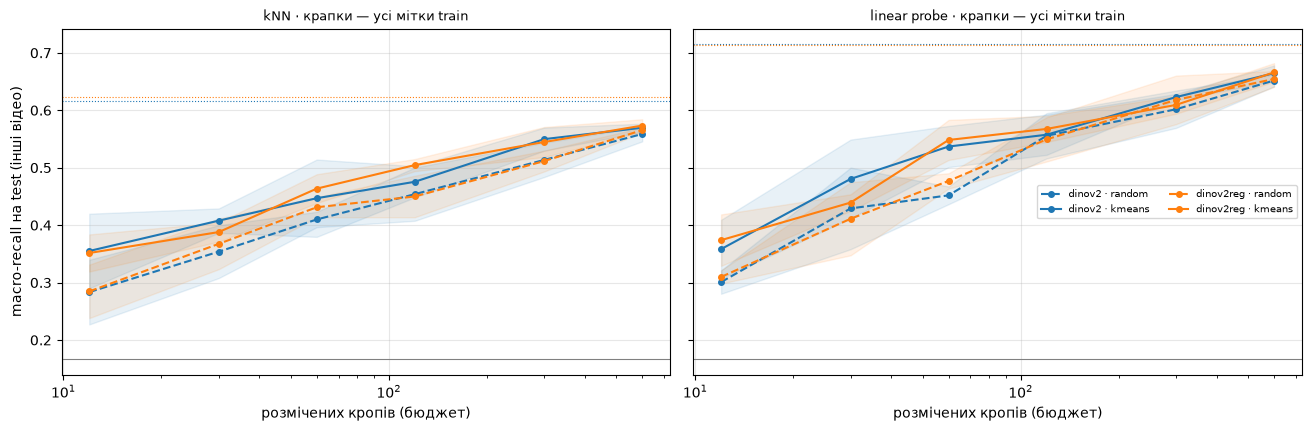

macro_recall           класів_у_розмітці          
model                  dinov2 dinov2reg            dinov2 dinov2reg
method    budget                                                   
kmeans    12            0.355     0.352             4.333     4.333
          30            0.408     0.388             6.000     5.667
          60            0.447     0.464             6.000     6.000
          120           0.475     0.505             6.000     6.000
          300           0.550     0.545             6.000     6.000
          600           0.570     0.573             6.000     6.000
random    12            0.283     0.285             4.333     4.333
          30            0.354     0.367             6.000     6.000
          60            0.410     0.431             5.667     5.667
          120           0.454     0.450             6.000     6.000
          300           0.514     0.512             6.000     6.000
          600           0.559     0.565             6.000     6.000
усі мітки 2776          0.615     0.623             6.000     6.000

In [8]:
R = P.label_efficiency(crop_embs, y, tr, te, budgets=BUDGETS, methods=("random", "kmeans"), seeds=SEEDS)
P.plot_label_efficiency(R, chance=1 / len(CLASSES))
display(R[R.clf == "kNN"].groupby(["model", "method", "budget"])
        .agg(macro_recall=("macro_recall", "mean"), класів_у_розмітці=("classes", "mean")).unstack("model").round(3))

### Точність за розміром цілі

Ті самі фічі, kNN на всіх train-мітках, macro-recall окремо за короткою стороною об'єкта у вихідному кадрі.
Кроп 15 px, розтягнутий до 224, — розмита пляма: тут вирішує бюджет пікселів, а не модель (слайд 22).
Склад класів у кошиках різний (пішоходи переважно дрібні, автобуси великі), тож порівнюйте обережно.

In [9]:
S = P.recall_by_size(crop_embs, y, crops.short.to_numpy(), tr, te)
piv = S.pivot(index="size", columns="model", values="macro_recall").reindex(S["size"].unique())
piv.insert(0, "n_test", S.drop_duplicates("size").set_index("size")["n"])
display(piv.round(3))

model,n_test,dinov2,dinov2reg
size,,,
0–20px,256,0.576,0.502
20–40px,374,0.579,0.542
40–80px,312,0.596,0.653
≥80px,162,0.725,0.756


**Підсумок розділу.**
* Сотні міток на заморожених фічах дають більшу частину якості «всіх train-міток» (у прогоні на VisDrone 600 міток —
  ~0.5 macro-recall проти ~0.6 з усіма 5 тис.). Найчесніше число для наради — бюджет, на якому крива виходить на плато.
* Кластерний добір тут кращий за випадковий майже на всіх бюджетах, найпомітніше на найменших (12 міток), але виграш —
  кілька пунктів, а не «200 кращі за 2000»: перевіряйте цю тезу слайда 29 кривою на своєму домені.
* Колонка `класів_у_розмітці`: на найменших бюджетах у розмітку потрапляють не всі класи, і kNN рідкісний клас не передбачить.
* Великі цілі (≥ 80 px) розпізнаються помітно краще; на дрібних склад класів у кошиках змішує картину, але межу задають пікселі.

## 4. Архів як актив: ті самі місця в різних відео і витік

CLS-ембеддинг цілого кадру — компактний опис сцени: на ньому можна шукати дублікати й аномалії в архіві (слайд 27 «DINOv2: що додано і навіщо це нам»).
Беремо пари кадрів із **різних** відео `uavNNNNNNN` з найбільшим косинусом — кандидати в «ту саму локацію».

,cos,a,b,cross_split
0,0.954,train/uav0000143_02250_v#71,train/uav0000295_02300_v#94,False
1,0.949,train/uav0000140_01590_v#116,train/uav0000295_02300_v#94,False
2,0.948,test-dev/uav0000088_00290_v#241,train/uav0000084_00000_v#515,True
3,0.945,train/uav0000084_00000_v#375,val/uav0000086_00000_v#379,True
4,0.939,test-dev/uav0000088_00290_v#107,val/uav0000086_00000_v#463,True
5,0.938,test-dev/uav0000306_00230_v#343,train/uav0000309_00000_v#37,True


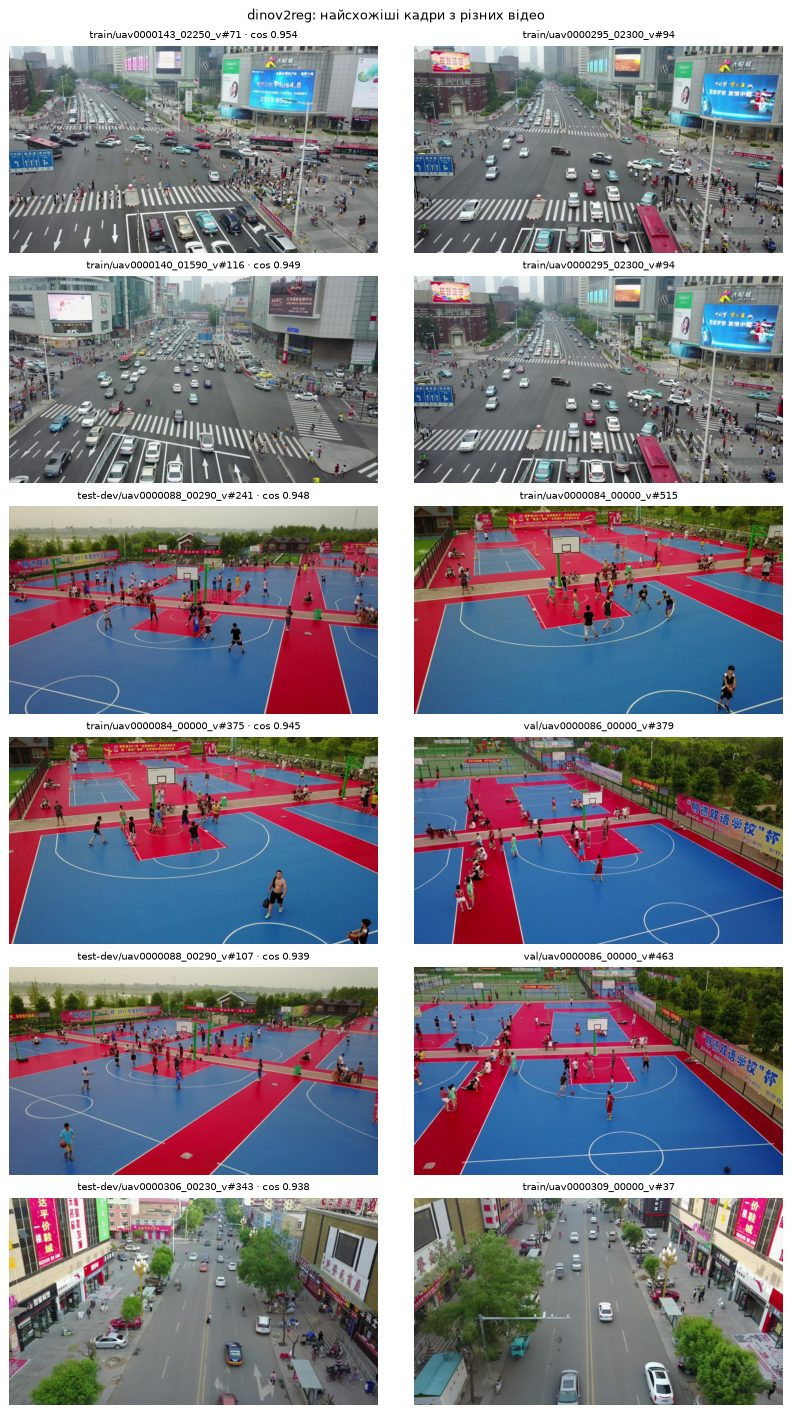

In [10]:
frames = P.sample_frames(seqs, per_seq=12)
ref = list(encs)[-1]   # найновіша з завантажених моделей
pairs = P.cross_video_pairs(P.embed_frames(encs[ref], frames, CACHE_DIR / "emb"), frames, top=6)
display(pairs[["cos", "a", "b", "cross_split"]])
P.show_pairs(pairs, f"{ref}: найсхожіші кадри з різних відео")

На VisDrone у топі — **ті самі місця, зняті в інших польотах**: те саме перехрестя, баскетбольний комплекс, вулиця
з тим самим фасадом, зокрема між train і val / test-dev. Отже, навіть офіційне розбиття «за відео» має **витік за локацією**.
Точкові ознаки (SIFT + RANSAC) цього не помічають через інший ракурс, висоту й час доби, а DINO помічає.

### Пастка: витік через розбиття train / test

Ті самі train-кропи, три способи відкласти 20 % на тест: **кроп випадково** (кропи одного треку по обидва боки),
**за послідовністю**, **за відео `uavNNNNNNN`**. Для порівняння — офіційне train → val + test-dev з розділу 3.

In [11]:
L = P.leakage_experiment(crop_embs, crops, y)
off = R[(R.method == "усі мітки") & (R.clf == "kNN")].assign(split="train → val + test-dev (офіційне)")
order = ["кроп випадково", "за послідовністю", "за відео (uavNNNNNNN)", "train → val + test-dev (офіційне)"]
tab = pd.concat([L, off[["model", "split", "macro_recall"]]]).groupby(["split", "model"]).macro_recall.mean().unstack("model")
display(tab.reindex([o for o in order if o in tab.index]).round(3))

model,dinov2,dinov2reg
split,,
кроп випадково,0.701,0.689
за послідовністю,0.582,0.586
за відео (uavNNNNNNN),0.606,0.597
train → val + test-dev (офіційне),0.615,0.623


**Підсумок розділу.** Різниця між першим і останнім рядком — це те, наскільки «красиве число» може брехати
(слайд 48: невизначеність має бути видно). Розбивайте за вильотом і **районом** зйомки, а не за кадром,
і перевіряйте датасет пошуком дублікатів по CLS ще до того, як вірити метриці.

## Підсумок

1. **Структура без міток.** PCA, увага [CLS] і карти подібності показують: DINO розділяє дороги, дахи, машини й людей,
   не бачивши жодної мітки (слайди 26–27).
2. **DINOv3 проти DINOv2.** Регістри й Gram anchoring прибирають артефакти щільних фіч; patch 16 замість 14 — інша сітка,
   а отже інший мінімальний розмір цілі (слайди 17, 28).
3. **Рецепт зі слайда 29 «Робочий рецепт» працює:** заморожені фічі + сотні міток + kNN / linear probe. Скільки саме міток і чи допомагає
   кластерний добір — міряйте кривою на своєму домені.
4. **Чесні числа.** Без розбиття за вильотом і локацією метрика завищена, а дрібні цілі впираються в пікселі (слайди 22, 46).

**Самостійно:** запустіть розділи 3–4 з `MODELS = ["dinov3", "dinov3sat"]`, `SIZE = "large"`. Чи допомагає супутниковий
DINOv3 на похилих кадрах дрона з висоти 30–100 м?

Далі — [Демо 2](lesson05_demo2_clip_basics.ipynb): спільний простір тексту й зображень.